In [12]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data
dataframe = pd.read_csv("../Data/Zomato-data.csv")

# Data Cleaning Functions
# Extracts numeric rating from strings formatted like '4.1/5'
def handleRate(value):
    if pd.isna(value) or str(value).strip() in ['NEW', '-']:
        return np.nan
    try: 
        val_str = str(value).split('/')[0].strip()
        return float(val_str)
    except ValueError: 
        return np.nan

# Clean Rating Column
dataframe['rate'] = dataframe['rate'].apply(handleRate)

# Clean approx_cost column if it contains a string with commas
if dataframe['approx_cost(for two people)'].dtype == 'object':
    dataframe['approx_cost(for two people)'] = (
        dataframe['approx_cost(for two people)']
            .astype(str)
            .str.replace(",", "")
            .str.strip()
    )

    dataframe['approx_cost(for two people)'] =  pd.to_numeric(
        dataframe['approx_cost(for two people)'],errors = 'coerce'
    )

In [13]:
# Quick Inspection
print("Data Summary:")
dataframe.info()

Data Summary:
<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


In [14]:
# Check for Missing values
print("Missing Values:")
dataframe.isnull().sum()

Missing Values:


name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

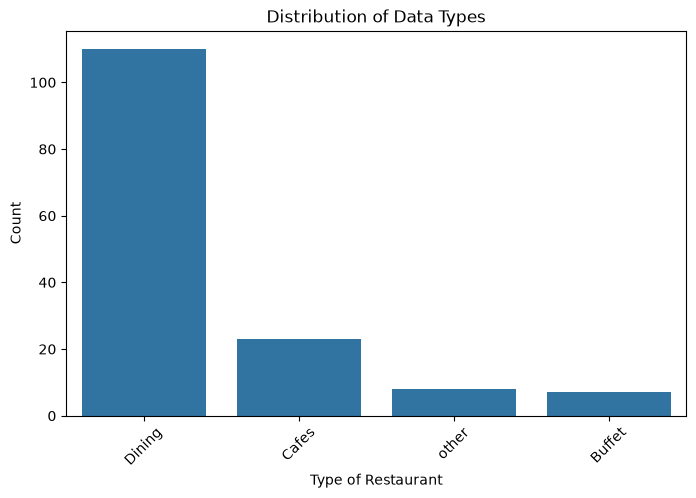

In [15]:
# Chart 1: Distribution of Restaurant Types
plt.figure(figsize=(8, 5))
sns.countplot(
    data=dataframe,
    x="listed_in(type)",
    order=dataframe["listed_in(type)"].value_counts().index
)
plt.title("Distribution of Data Types")
plt.xlabel("Type of Restaurant")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.savefig("../images/restaurant_types.png", dpi=300)
plt.show()

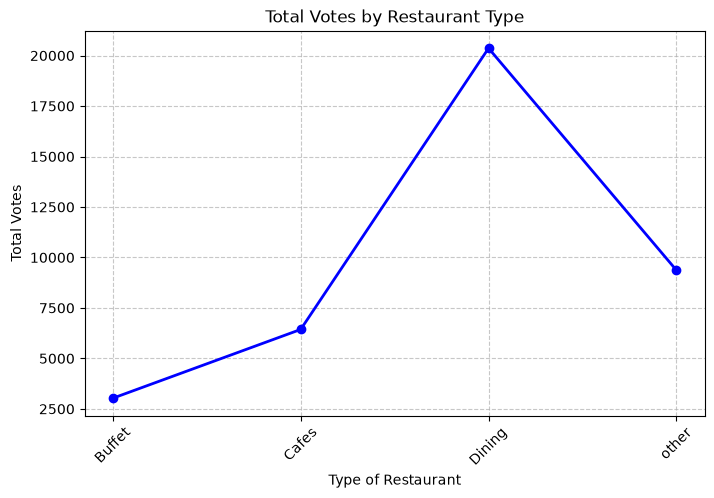

In [16]:
# Chart 2: Total Votes by Restaurant Type
grouped_votes = dataframe.groupby(['listed_in(type)'])['votes'].sum().reset_index()

plt.figure(figsize=(8, 5))
plt.plot(
    grouped_votes["listed_in(type)"], #X Axis data
    grouped_votes["votes"], #Y Axis data
    c="#0000FF",
    marker="o",
    linewidth=2
)
plt.title("Total Votes by Restaurant Type")
plt.xlabel("Type of Restaurant")
plt.ylabel("Total Votes")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.savefig("../images/votes_by_type.png", dpi=300)
plt.show()

In [17]:
# Highest Voted Restaurant
max_votes = dataframe["votes"].max()
top_voted_restaurant = dataframe.loc[dataframe["votes"] == max_votes, "name"].values[0]
print(f"\nRestaurant with the maximum votes ({max_votes:,}): {top_voted_restaurant}")


Restaurant with the maximum votes (4,884): Empire Restaurant


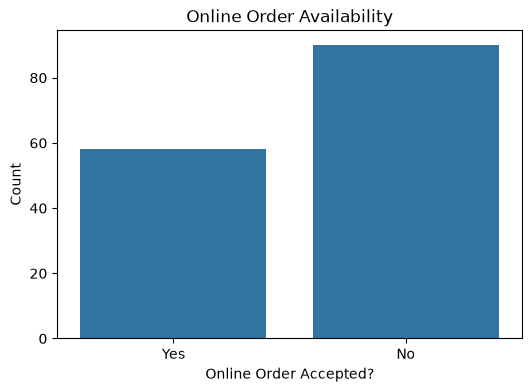

In [18]:
# Chart 3: Online Order Availability
plt.figure(figsize=(6, 4))
sns.countplot(data=dataframe, x="online_order")
plt.title("Online Order Availability")
plt.xlabel("Online Order Accepted?")
plt.ylabel("Count")
plt.savefig("../images/online_order_count.png", dpi=300)
plt.show()

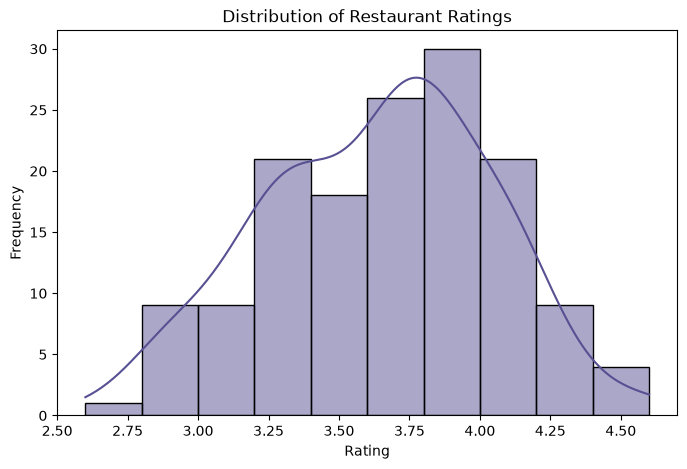

In [19]:
# Chart 4: Ratings Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=dataframe, x="rate", bins=10, kde=True, color="#575092")
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.savefig("../images/ratings_distribution.png", dpi=300)
plt.show()

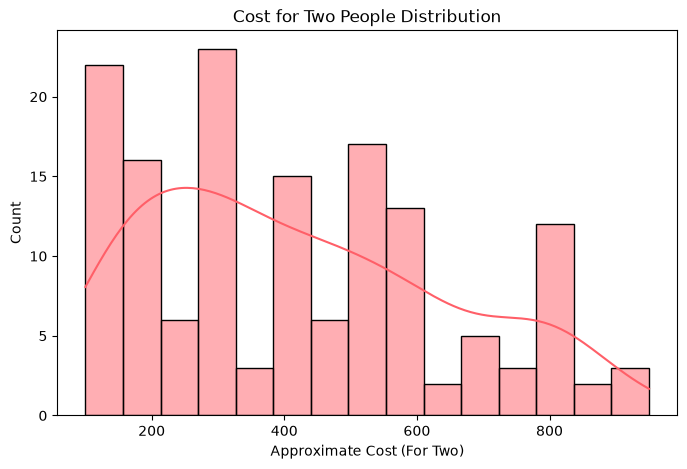

In [20]:
# Chart 5: Cost for Two People Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=dataframe["approx_cost(for two people)"].dropna(), bins=15, kde=True, color="#ff5f68")
plt.title("Cost for Two People Distribution")
plt.xlabel("Approximate Cost (For Two)")
plt.ylabel("Count")
plt.savefig("../images/cost_for_two.png", dpi=300)
plt.show()

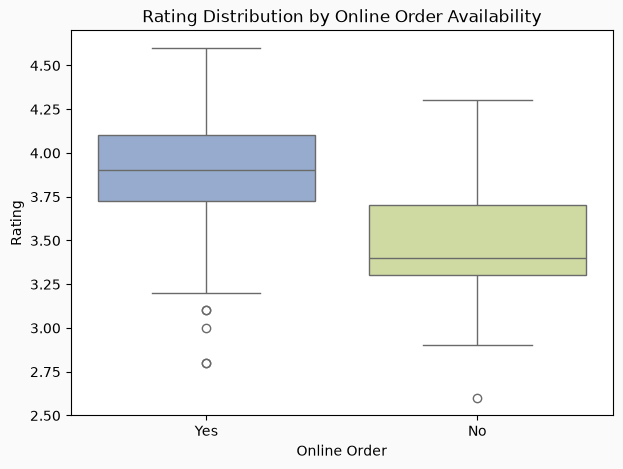

In [21]:
# Chart 6: Rating vs Online Order (Boxplot)
custom_colors = {"Yes": "#8da9d6", "No": "#d4e398"}

plt.figure(figsize=(7, 5), facecolor="#FAFAFA")
sns.boxplot(data=dataframe, x="online_order", y="rate", hue="online_order", palette=custom_colors, legend=False) # what does hue do on "online_order"?
plt.title("Rating Distribution by Online Order Availability")
plt.xlabel("Online Order")
plt.ylabel("Rating")
plt.savefig("../images/rating_vs_online_order.png", dpi=300)
plt.show()

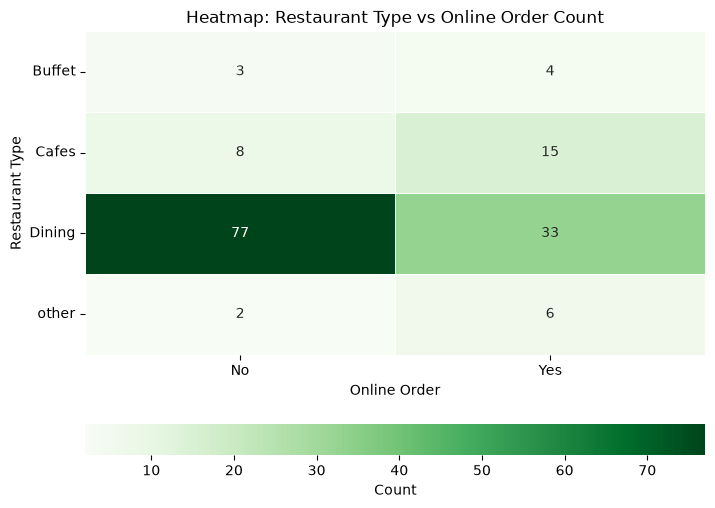

In [22]:
# Chart 7: Heatmap of Restaurant Type vs Online Order
pivot_table = dataframe.pivot_table(index="listed_in(type)", columns="online_order", aggfunc="size")

plt.figure(figsize=(8, 6))
sns.heatmap(data=pivot_table, annot=True, fmt="d", cmap="Greens", linewidths=0.5, cbar=True, cbar_kws={"label": "Count", "orientation": "horizontal"})
plt.title("Heatmap: Restaurant Type vs Online Order Count")
plt.xlabel("Online Order")
plt.ylabel("Restaurant Type")
plt.yticks(rotation=0)
plt.savefig("../images/type_vs_online_order_heatmap.png", dpi=300)
plt.show()